# CA1 – Task 2: Recommendation System Development
**DL836 Y4 – Research & Analytics | Data Analytics for Business**

**Scenario:** Data Analytics Consultant reporting to the **Marketing Director**.

**Objective:** Combine the customer, product and transaction datasets, analyse customer and product behaviour, and build and evaluate recommendation systems that can drive customer engagement and revenue.

| Section | Contents |
|---|---|
| 1 | Setup & data loading |
| 2 | Data quality assessment & cleaning |
| 3 | Data integration & customer–product interaction matrix |
| 4 | Customer analytics (Top 10 by spend / frequency, RFM value segments) |
| 5 | Product analytics (Top 10 products, revenue by category & brand) |
| 6 | GroupBy & Pivot Table analysis |
| 7 | Recommendation systems: Popularity-based, Item-based Collaborative Filtering, Content-based |
| 8 | Evaluation & comparison (Precision@K, Recall@K, Hit Rate, Coverage) |
| 9 | Recommendations for example customers |
| 10 | Summary of outputs |

## 1. Setup & Data Loading

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

DATA_DIR = "../data/"
FIG_DIR = "../outputs/figures/"
TABLE_DIR = "../outputs/tables/"
RANDOM_STATE = 42
K = 10  # number of recommendations per customer

customers_raw = pd.read_csv(DATA_DIR + "Customers_list.csv")
products_raw = pd.read_csv(DATA_DIR + "Products_list.csv")
transactions_raw = pd.read_csv(DATA_DIR + "Transactions_list.csv")

for name, d in [("Customers", customers_raw), ("Products", products_raw), ("Transactions", transactions_raw)]:
    print(f"{name}: {d.shape[0]:,} rows x {d.shape[1]} columns")

Customers: 1,000 rows x 5 columns
Products: 200 rows x 6 columns
Transactions: 18,829 rows x 5 columns


In [2]:
display(customers_raw.head())
display(products_raw.head())
display(transactions_raw.head())

,CustomerID,AgeGroup,Region,LoyaltyLevel,MembershipYears
0,1,50+,South,Bronze,8
1,2,26-35,South,Bronze,1
2,3,26-35,West,Bronze,2
3,4,50+,West,Silver,2
4,5,26-35,South,Bronze,8


,ProductID,Category,Brand,Price,Rating,PopularityScore
0,1,Fitness,PrimeGoods,66.68,4.35,1
1,2,Kitchen,FitLife,367.01,NaN,2
2,3,Books,TechMax,176.00,4.57,1
3,4,Fitness,NextGen,426.37,3.39,7
4,5,Gaming,TechMax,266.57,4.19,1


,CustomerID,ProductID,PurchaseCount,LastPurchaseDays,Spend
0,1,171,1,82,462.89
1,2,48,4,255,433.60
2,2,112,3,315,"1,264.65"
3,3,1,1,53,460.84
4,4,44,4,269,767.68


In [3]:
customers_raw.info(); print()
products_raw.info(); print()
transactions_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   CustomerID       1000 non-null   int64
 1   AgeGroup         1000 non-null   str  
 2   Region           1000 non-null   str  
 3   LoyaltyLevel     1000 non-null   str  
 4   MembershipYears  1000 non-null   int64
dtypes: int64(2), str(3)
memory usage: 39.2 KB

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ProductID        200 non-null    int64  
 1   Category         200 non-null    str    
 2   Brand            200 non-null    str    
 3   Price            200 non-null    float64
 4   Rating           185 non-null    float64
 5   PopularityScore  200 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 9.5 KB

<class 'pandas.DataFrame'>
Ran

In [4]:
display(customers_raw.describe(include="all").T)
display(products_raw.describe(include="all").T)
display(transactions_raw.describe().T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,"1,000.00",NaN,NaN,NaN,500.50,288.82,1.00,250.75,500.50,750.25,"1,000.00"
AgeGroup,1000,4,26-35,267,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Region,1000,4,South,261,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LoyaltyLevel,1000,3,Bronze,493,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MembershipYears,"1,000.00",NaN,NaN,NaN,7.48,4.08,1.00,4.00,8.00,11.00,14.00


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ProductID,200.00,NaN,NaN,NaN,100.50,57.88,1.00,50.75,100.50,150.25,200.00
Category,200,12,Fitness,33,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Brand,200,6,TechMax,45,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,200.00,NaN,NaN,NaN,259.03,142.42,16.39,142.27,262.22,381.88,495.00
Rating,185.00,NaN,NaN,NaN,3.83,0.77,2.51,3.15,3.87,4.52,5.00
PopularityScore,200.00,NaN,NaN,NaN,3.67,12.37,1.00,1.00,1.00,2.00,131.00


,count,mean,std,min,25%,50%,75%,max
CustomerID,"18,829.00",523.57,275.72,1.00,286.00,522.00,764.00,"1,000.00"
ProductID,"18,829.00",89.52,56.66,1.00,48.00,76.00,137.00,200.00
PurchaseCount,"18,829.00",2.49,1.11,1.00,2.00,2.00,3.00,4.00
LastPurchaseDays,"18,829.00",181.15,104.81,1.00,90.00,180.00,271.00,364.00
Spend,"18,829.00",602.14,446.42,11.17,269.54,493.53,835.70,"1,996.80"


## 2. Data Quality Assessment & Cleaning
### 2.1 Missing values and duplicates

In [5]:
dq = []
for name, d, key in [("Customers", customers_raw, "CustomerID"),
                     ("Products", products_raw, "ProductID"),
                     ("Transactions", transactions_raw, None)]:
    dq.append({"Dataset": name, "Rows": len(d),
               "MissingCells": int(d.isna().sum().sum()),
               "ColumnsWithMissing": ", ".join(d.columns[d.isna().any()]) or "-",
               "ExactDuplicateRows": int(d.duplicated().sum()),
               "DuplicateKeys": int(d[key].duplicated().sum()) if key else "n/a"})
pd.DataFrame(dq).set_index("Dataset")

,Rows,MissingCells,ColumnsWithMissing,ExactDuplicateRows,DuplicateKeys
Dataset,,,,,
Customers,1000,0,-,0,0
Products,200,15,Rating,0,0
Transactions,18829,0,-,386,n/a


### 2.2 Categorical consistency

In [6]:
for col in ["AgeGroup", "Region", "LoyaltyLevel"]:
    print(col, customers_raw[col].value_counts().to_dict())
for col in ["Category", "Brand"]:
    print(col, products_raw[col].value_counts().to_dict())

AgeGroup {'26-35': 267, '36-50': 251, '18-25': 245, '50+': 237}
Region {'South': 261, 'West': 252, 'North': 247, 'East': 240}
LoyaltyLevel {'Bronze': 493, 'Silver': 320, 'Gold': 187}
Category {'Fitness': 33, 'Books': 33, 'Kitchen': 32, 'Home': 29, 'Electronics': 27, 'Gaming': 26, 'fitness': 5, 'electronics': 5, 'home': 4, 'kitchen': 3, 'books': 2, 'gaming': 1}
Brand {'TechMax': 45, 'FitLife': 34, 'PrimeGoods': 33, 'HomePro': 32, 'SmartBuy': 29, 'NextGen': 27}


**Issue found:** `Category` uses inconsistent capitalisation, e.g. *Fitness* vs *fitness*. Left as-is, these would be treated as 12 categories instead of 6.

### 2.3 Referential integrity and value checks

In [7]:
print("Transactions with unknown CustomerID:", (~transactions_raw["CustomerID"].isin(customers_raw["CustomerID"])).sum())
print("Transactions with unknown ProductID:", (~transactions_raw["ProductID"].isin(products_raw["ProductID"])).sum())
print("Customers with no transactions:", (~customers_raw["CustomerID"].isin(transactions_raw["CustomerID"])).sum())
print("Products never purchased:", (~products_raw["ProductID"].isin(transactions_raw["ProductID"])).sum())
print("Non-positive Spend / PurchaseCount:", (transactions_raw["Spend"] <= 0).sum(), (transactions_raw["PurchaseCount"] <= 0).sum())
print("Repeated customer–product pairs (non-exact):",
      transactions_raw.drop_duplicates().duplicated(["CustomerID", "ProductID"]).sum())

Transactions with unknown CustomerID: 0
Transactions with unknown ProductID: 0
Customers with no transactions: 0
Products never purchased: 0
Non-positive Spend / PurchaseCount: 0 0
Repeated customer–product pairs (non-exact): 8180


In [8]:
# Does Spend equal Price x PurchaseCount? (checks whether Spend is reliable as a revenue figure)
chk = transactions_raw.merge(products_raw[["ProductID", "Price"]], on="ProductID")
ratio = chk["Spend"] / (chk["Price"] * chk["PurchaseCount"])
print("Spend / (Price x PurchaseCount):")
ratio.describe()

Spend / (Price x PurchaseCount):


count   18,829.00
mean         2.59
std          3.55
min          0.04
25%          0.72
50%          1.07
75%          2.62
max         23.56
dtype: float64

In [9]:
# Is the supplied PopularityScore consistent with actual purchase behaviour?
actual_buyers = transactions_raw.groupby("ProductID")["CustomerID"].nunique()
pop_check = products_raw.set_index("ProductID")[["PopularityScore"]].join(actual_buyers.rename("ActualBuyers"))
print("Correlation between supplied PopularityScore and actual number of buyers:",
      round(pop_check.corr().iloc[0, 1], 3))
print("PopularityScore distribution:", products_raw["PopularityScore"].value_counts().head(5).to_dict())

Correlation between supplied PopularityScore and actual number of buyers: 0.037
PopularityScore distribution: {1: 128, 2: 26, 3: 11, 4: 8, 5: 8}


**Data quality findings**
* `Products.Rating` has 15 missing values (7.5%).
* `Products.Category` has inconsistent capitalisation (12 labels → 6 real categories).
* `Transactions` has 386 exact duplicate rows. Many customer–product pairs also appear in several rows (repeat purchases), so they are aggregated when building the interaction matrix.
* `Spend` does **not** equal Price × PurchaseCount: the ratio varies widely. `Spend` is treated as the recorded revenue figure, but this inconsistency should be raised with the data owner.
* The supplied `PopularityScore` has almost no relationship with real purchases (r ≈ 0.04), so popularity is **calculated from the transaction data** instead.
* No orphan IDs, and no zero or negative values.

### 2.4 Cleaning

In [10]:
customers = customers_raw.copy()

products = products_raw.copy()
products["Category"] = products["Category"].str.strip().str.title()
products["RatingImputed"] = products["Rating"].isna().astype(int)
products["Rating"] = products["Rating"].fillna(products.groupby("Category")["Rating"].transform("median"))

transactions = transactions_raw.drop_duplicates().reset_index(drop=True)

print("Categories after cleaning:", products["Category"].value_counts().to_dict())
print("Missing ratings after imputation:", products["Rating"].isna().sum())
print(f"Transactions: {len(transactions_raw):,} -> {len(transactions):,} after removing duplicates")

Categories after cleaning: {'Fitness': 38, 'Kitchen': 35, 'Books': 35, 'Home': 33, 'Electronics': 32, 'Gaming': 27}
Missing ratings after imputation: 0
Transactions: 18,829 -> 18,443 after removing duplicates


## 3. Data Integration & Interaction Matrix
### 3.1 Merge the three datasets

In [11]:
full = (transactions
        .merge(customers, on="CustomerID", how="left", validate="many_to_one")
        .merge(products, on="ProductID", how="left", validate="many_to_one"))
print("Integrated dataset:", full.shape)
print("Missing values after merge:", int(full.isna().sum().sum()))
full.head()

Integrated dataset: (18443, 15)
Missing values after merge: 0


,CustomerID,ProductID,PurchaseCount,LastPurchaseDays,Spend,AgeGroup,Region,LoyaltyLevel,MembershipYears,Category,Brand,Price,Rating,PopularityScore,RatingImputed
0,1,171,1,82,462.89,50+,South,Bronze,8,Electronics,TechMax,449.12,4.36,2,0
1,2,48,4,255,433.60,26-35,South,Bronze,1,Gaming,FitLife,273.31,3.90,8,0
2,2,112,3,315,"1,264.65",26-35,South,Bronze,1,Home,NextGen,205.16,3.07,15,0
3,3,1,1,53,460.84,26-35,West,Bronze,2,Fitness,PrimeGoods,66.68,4.35,1,0
4,4,44,4,269,767.68,50+,West,Silver,2,Gaming,TechMax,136.66,4.72,1,0


### 3.2 Customer–product interactions
Repeat rows for the same customer–product pair are combined into a single interaction.

In [12]:
interactions = (transactions.groupby(["CustomerID", "ProductID"])
                .agg(Transactions=("Spend", "size"),
                     Quantity=("PurchaseCount", "sum"),
                     Spend=("Spend", "sum"),
                     MostRecentDays=("LastPurchaseDays", "min"))
                .reset_index())
print(f"{len(interactions):,} unique customer–product interactions")
interactions.head()

10,263 unique customer–product interactions

,CustomerID,ProductID,Transactions,Quantity,Spend,MostRecentDays
0,1,171,1,1,462.89,82
1,2,48,1,4,433.60,255
2,2,112,1,3,"1,264.65",315
3,3,1,1,1,460.84,53
4,4,44,2,5,959.60,268


In [13]:
# Customer x Product interaction matrix (values = total quantity purchased; 0 = never purchased)
interaction_matrix = interactions.pivot_table(index="CustomerID", columns="ProductID",
                                              values="Quantity", aggfunc="sum", fill_value=0)
n_cells = interaction_matrix.size
n_filled = (interaction_matrix > 0).sum().sum()
print("Interaction matrix shape:", interaction_matrix.shape)
print(f"Filled cells: {n_filled:,} of {n_cells:,}  ->  sparsity = {1 - n_filled / n_cells:.1%}")
print(f"Products per customer: mean {(interaction_matrix > 0).sum(axis=1).mean():.1f}, "
      f"min {(interaction_matrix > 0).sum(axis=1).min()}, max {(interaction_matrix > 0).sum(axis=1).max()}")
interaction_matrix.iloc[:8, :12]

Interaction matrix shape: (1000, 200)
Filled cells: 10,263 of 200,000  ->  sparsity = 94.9%
Products per customer: mean 10.3, min 1, max 20


ProductID,1,2,3,4,5,6,7,8,9,10,11,12
CustomerID,,,,,,,,,,,,
1,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,2,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,0,0


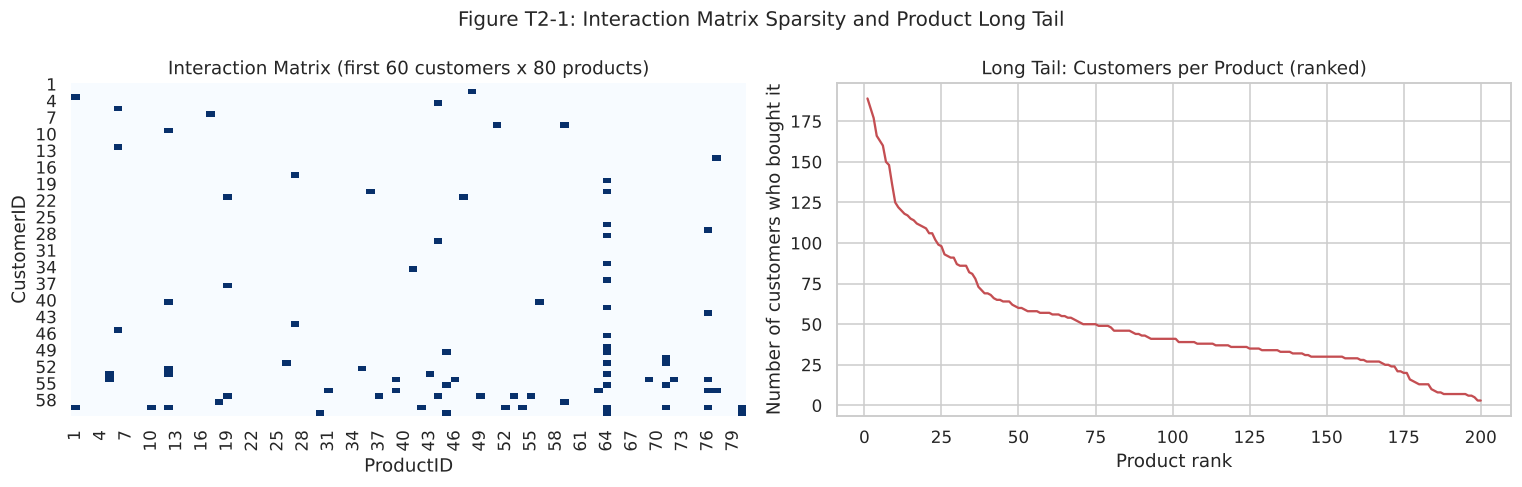

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap((interaction_matrix.iloc[:60, :80] > 0).astype(int), cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title("Interaction Matrix (first 60 customers x 80 products)")
axes[0].set_xlabel("ProductID"); axes[0].set_ylabel("CustomerID")
buyers_per_product = (interaction_matrix > 0).sum().sort_values(ascending=False).values
axes[1].plot(range(1, len(buyers_per_product) + 1), buyers_per_product, color="#C44E52")
axes[1].set_title("Long Tail: Customers per Product (ranked)")
axes[1].set_xlabel("Product rank"); axes[1].set_ylabel("Number of customers who bought it")
fig.suptitle("Figure T2-1: Interaction Matrix Sparsity and Product Long Tail", fontsize=13)
plt.tight_layout()
plt.savefig(FIG_DIR + "t2_fig01_interaction_matrix.png", bbox_inches="tight")
plt.show()

## 4. Customer Analytics
### 4.1 Customer-level summary

In [15]:
cust = (full.groupby("CustomerID")
        .agg(TotalSpend=("Spend", "sum"),
             Transactions=("Spend", "size"),
             TotalQuantity=("PurchaseCount", "sum"),
             UniqueProducts=("ProductID", "nunique"),
             UniqueCategories=("Category", "nunique"),
             RecencyDays=("LastPurchaseDays", "min"),
             AvgSpendPerTransaction=("Spend", "mean"))
        .join(customers.set_index("CustomerID")))
cust.describe().T

,count,mean,std,min,25%,50%,75%,max
TotalSpend,"1,000.00","11,098.86","4,622.82",105.42,"7,844.51","11,133.48","14,375.96","23,828.03"
Transactions,"1,000.00",18.44,6.85,1.00,13.00,19.00,24.00,29.00
TotalQuantity,"1,000.00",45.95,17.71,1.00,34.00,47.00,59.00,83.00
UniqueProducts,"1,000.00",10.26,4.15,1.00,8.00,11.00,13.00,20.00
UniqueCategories,"1,000.00",4.82,1.34,1.00,4.00,5.00,6.00,6.00
RecencyDays,"1,000.00",25.18,38.11,1.00,5.75,14.00,29.00,304.00
AvgSpendPerTransaction,"1,000.00",603.71,143.46,105.42,507.62,596.16,688.04,"1,995.56"
MembershipYears,"1,000.00",7.48,4.08,1.00,4.00,8.00,11.00,14.00


### 4.2 Top 10 customers by total spend

In [16]:
top_spend = cust.sort_values("TotalSpend", ascending=False).head(10)
top_spend.to_csv(TABLE_DIR + "t2_top10_customers_spend.csv")
top_spend[["TotalSpend", "Transactions", "TotalQuantity", "UniqueProducts", "RecencyDays",
           "AgeGroup", "Region", "LoyaltyLevel", "MembershipYears"]]

,TotalSpend,Transactions,TotalQuantity,UniqueProducts,RecencyDays,AgeGroup,Region,LoyaltyLevel,MembershipYears
CustomerID,,,,,,,,,
729,"23,828.03",29,73,15,5,18-25,East,Bronze,1
660,"23,301.22",29,74,15,28,36-50,West,Bronze,1
894,"23,127.86",26,70,13,15,50+,South,Bronze,5
481,"22,819.08",27,76,14,29,26-35,South,Silver,11
74,"22,564.03",29,82,17,2,26-35,South,Bronze,5
83,"21,968.20",29,67,17,43,26-35,West,Gold,2
707,"21,746.12",26,68,16,6,26-35,West,Bronze,5
544,"21,681.06",29,72,16,1,26-35,South,Bronze,5
576,"21,668.43",28,78,15,2,18-25,East,Bronze,10


### 4.3 Top 10 customers by purchase frequency
Frequency is measured as the total number of units purchased (`PurchaseCount`). Number of transactions is shown alongside it.

In [17]:
top_freq = cust.sort_values(["TotalQuantity", "Transactions"], ascending=False).head(10)
top_freq.to_csv(TABLE_DIR + "t2_top10_customers_frequency.csv")
top_freq[["TotalQuantity", "Transactions", "TotalSpend", "UniqueProducts", "RecencyDays",
          "AgeGroup", "Region", "LoyaltyLevel"]]

,TotalQuantity,Transactions,TotalSpend,UniqueProducts,RecencyDays,AgeGroup,Region,LoyaltyLevel
CustomerID,,,,,,,,
450,83,28,"16,211.05",18,5,18-25,South,Bronze
74,82,29,"22,564.03",17,2,26-35,South,Bronze
298,82,29,"18,909.03",15,36,26-35,East,Bronze
880,82,29,"17,152.34",7,7,26-35,West,Silver
374,82,28,"16,055.06",14,15,18-25,South,Bronze
240,81,29,"20,688.72",15,8,36-50,East,Bronze
329,81,26,"19,415.12",14,48,36-50,North,Silver
168,80,29,"21,100.45",15,6,26-35,West,Silver
65,79,29,"21,168.14",13,7,26-35,East,Gold


In [18]:
overlap = set(top_spend.index) & set(top_freq.index)
print(f"Customers in BOTH top-10 lists: {len(overlap)} -> {sorted(overlap)}")
top10_share = cust["TotalSpend"].nlargest(int(len(cust) * 0.1)).sum() / cust["TotalSpend"].sum()
top20_share = cust["TotalSpend"].nlargest(int(len(cust) * 0.2)).sum() / cust["TotalSpend"].sum()
print(f"Top 10% of customers generate {top10_share:.1%} of revenue; top 20% generate {top20_share:.1%}")

Customers in BOTH top-10 lists: 1 -> [74]
Top 10% of customers generate 17.1% of revenue; top 20% generate 31.4%


### 4.4 Customer value analysis – RFM segmentation
Each customer is scored 1–5 on **R**ecency (fewer days since last purchase = better), **F**requency (units bought) and **M**onetary value (total spend). The scores are combined into business segments.

In [19]:
rfm = cust[["RecencyDays", "TotalQuantity", "TotalSpend"]].copy()
rfm["R"] = pd.qcut(rfm["RecencyDays"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["TotalQuantity"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["TotalSpend"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["RFM_Score"] = rfm[["R", "F", "M"]].sum(axis=1)

def segment(row):
    if row["R"] >= 4 and row["F"] >= 4 and row["M"] >= 4:
        return "Champions"
    if row["F"] >= 4 and row["M"] >= 4:
        return "Loyal High-Value"
    if row["R"] <= 2 and row["M"] >= 3:
        return "At Risk"
    if row["R"] >= 4 and row["F"] <= 2:
        return "New / Promising"
    if row["R"] <= 2 and row["F"] <= 2:
        return "Hibernating"
    return "Need Attention"

rfm["Segment"] = rfm.apply(segment, axis=1)
cust = cust.join(rfm[["R", "F", "M", "RFM_Score", "Segment"]])

seg_summary = (cust.groupby("Segment")
               .agg(Customers=("TotalSpend", "size"),
                    AvgSpend=("TotalSpend", "mean"),
                    TotalSpend=("TotalSpend", "sum"),
                    AvgRecencyDays=("RecencyDays", "mean"),
                    AvgUnits=("TotalQuantity", "mean"))
               .sort_values("AvgSpend", ascending=False))
seg_summary["RevenueShare%"] = seg_summary["TotalSpend"] / seg_summary["TotalSpend"].sum() * 100
seg_summary.to_csv(TABLE_DIR + "t2_rfm_segments.csv")
seg_summary

,Customers,AvgSpend,TotalSpend,AvgRecencyDays,AvgUnits,RevenueShare%
Segment,,,,,,
Champions,169,"16,191.61","2,736,382.27",4.37,64.72,24.65
Loyal High-Value,158,"15,838.45","2,502,474.78",25.12,63.81,22.55
At Risk,93,"11,909.04","1,107,540.64",36.41,47.08,9.98
Need Attention,262,"10,377.01","2,718,777.06",12.14,45.80,24.50
New / Promising,122,"7,752.94","945,858.19",4.78,31.80,8.52
Hibernating,196,"5,550.14","1,087,827.43",68.00,23.85,9.80


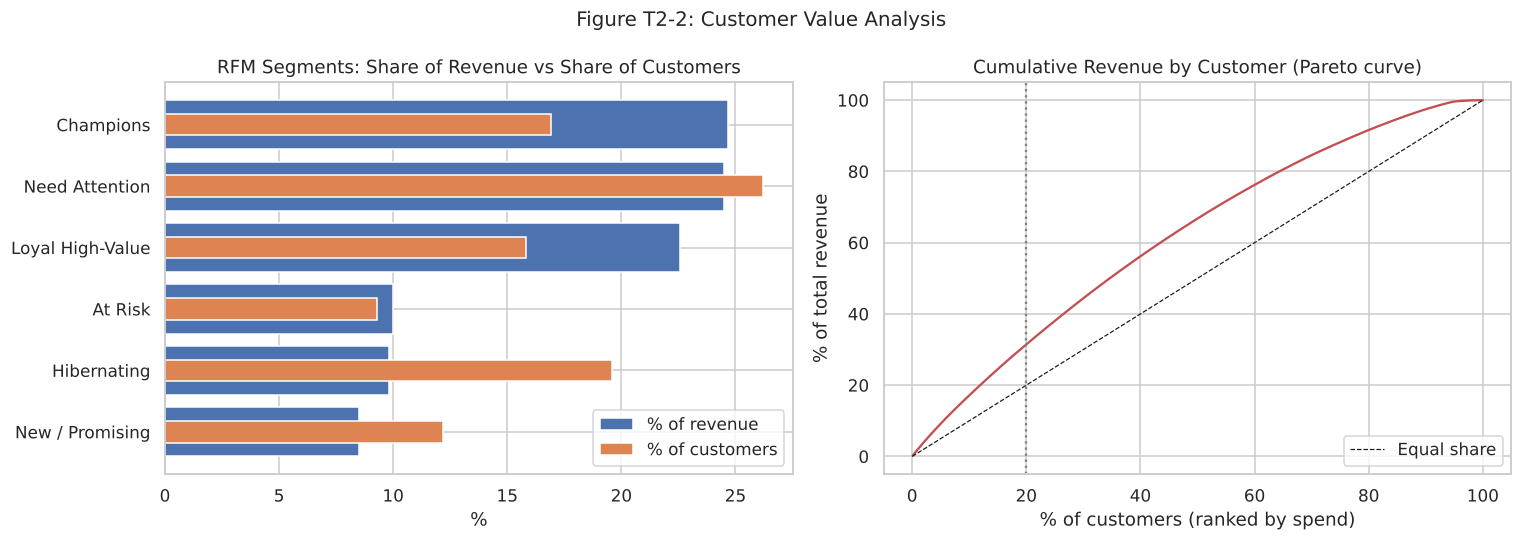

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
seg_plot = seg_summary.sort_values("TotalSpend")
axes[0].barh(seg_plot.index, seg_plot["RevenueShare%"], color="#4C72B0", label="% of revenue")
axes[0].barh(seg_plot.index, seg_plot["Customers"] / seg_plot["Customers"].sum() * 100,
             color="#DD8452", height=0.35, label="% of customers")
axes[0].set_title("RFM Segments: Share of Revenue vs Share of Customers")
axes[0].set_xlabel("%"); axes[0].legend()

sorted_spend = cust["TotalSpend"].sort_values(ascending=False).cumsum() / cust["TotalSpend"].sum() * 100
axes[1].plot(np.arange(1, len(sorted_spend) + 1) / len(sorted_spend) * 100, sorted_spend.values, color="#C44E52")
axes[1].plot([0, 100], [0, 100], "k--", lw=0.8, label="Equal share")
axes[1].axvline(20, color="grey", ls=":")
axes[1].set_title("Cumulative Revenue by Customer (Pareto curve)")
axes[1].set_xlabel("% of customers (ranked by spend)"); axes[1].set_ylabel("% of total revenue")
axes[1].legend()
fig.suptitle("Figure T2-2: Customer Value Analysis", fontsize=13)
plt.tight_layout()
plt.savefig(FIG_DIR + "t2_fig02_customer_value.png", bbox_inches="tight")
plt.show()

### 4.5 Key customer observations
* **The highest spenders are mostly Bronze members.** 7 of the top 10 customers by spend are Bronze, 2 are Silver and only 1 is Gold, and several joined only 1–2 years ago. The loyalty tier does not identify the most valuable customers.
* **High spend and high frequency are different groups:** only one customer (ID 74) appears in both top-10 lists. Some frequent buyers purchase many cheap units, and some top spenders buy fewer, pricier items.
* **Revenue is spread fairly evenly:** the top 10% of customers generate ≈17% of revenue and the top 20% ≈31%, much flatter than a classic 80/20 pattern. Growth will come from the broad base, not just a few VIPs.
* **RFM segments:** *Champions* (169) and *Loyal High-Value* (158) are about a third of customers and generate ≈47% of revenue. **93 "At Risk" customers** (high past spend, avg ≈36 days since last purchase) hold ≈10% of revenue. **196 "Hibernating"** customers average 68 days inactive.

## 5. Product Analytics
### 5.1 Top 10 products by revenue

In [21]:
prod = (full.groupby("ProductID")
        .agg(Revenue=("Spend", "sum"),
             UnitsSold=("PurchaseCount", "sum"),
             Buyers=("CustomerID", "nunique"),
             Transactions=("Spend", "size"))
        .join(products.set_index("ProductID")))
prod["RevenueShare%"] = prod["Revenue"] / prod["Revenue"].sum() * 100
top_products = prod.sort_values("Revenue", ascending=False).head(10)
top_products.to_csv(TABLE_DIR + "t2_top10_products_revenue.csv")
top_products[["Category", "Brand", "Price", "Rating", "Revenue", "RevenueShare%", "UnitsSold", "Buyers"]]

,Category,Brand,Price,Rating,Revenue,RevenueShare%,UnitsSold,Buyers
ProductID,,,,,,,,
64,Books,PrimeGoods,180.13,5.00,"969,511.68",8.74,5832,183
76,Kitchen,FitLife,20.70,4.26,"516,181.63",4.65,2383,177
73,Gaming,TechMax,415.14,3.84,"513,764.73",4.63,1041,160
137,Fitness,NextGen,24.58,4.08,"377,406.54",3.40,1447,166
18,Gaming,SmartBuy,179.41,3.76,"285,252.63",2.57,601,114
47,Gaming,NextGen,116.36,4.60,"285,250.14",2.57,621,125
12,Fitness,PrimeGoods,422.56,2.61,"270,583.58",2.44,2326,189
6,Kitchen,SmartBuy,359.14,4.31,"207,772.24",1.87,664,136
44,Gaming,TechMax,136.66,4.72,"201,899.84",1.82,1052,150


In [22]:
print(f"Top 10 products = {top_products['RevenueShare%'].sum():.1f}% of revenue "
      f"(they are {10 / len(prod):.0%} of the catalogue)")

Top 10 products = 34.5% of revenue (they are 5% of the catalogue)


### 5.2 Revenue by category (GroupBy 1)

In [23]:
cat_rev = (full.groupby("Category")
           .agg(Revenue=("Spend", "sum"), Units=("PurchaseCount", "sum"),
                Customers=("CustomerID", "nunique"), AvgSpendPerTxn=("Spend", "mean"))
           .join(products.groupby("Category").agg(Products=("ProductID", "count"),
                                                  AvgPrice=("Price", "mean"),
                                                  AvgRating=("Rating", "mean")))
           .sort_values("Revenue", ascending=False))
cat_rev["RevenueShare%"] = cat_rev["Revenue"] / cat_rev["Revenue"].sum() * 100
cat_rev["RevenuePerProduct"] = cat_rev["Revenue"] / cat_rev["Products"]
cat_rev.to_csv(TABLE_DIR + "t2_revenue_by_category.csv")
cat_rev

,Revenue,Units,Customers,AvgSpendPerTxn,Products,AvgPrice,AvgRating,RevenueShare%,RevenuePerProduct
Category,,,,,,,,,
Books,"2,335,204.47",10847,861,538.19,35,255.23,3.87,21.04,"66,720.13"
Gaming,"2,281,265.76",7327,800,783.94,27,220.18,3.80,20.55,"84,491.32"
Kitchen,"1,868,036.68",7163,770,649.75,35,286.51,3.88,16.83,"53,372.48"
Fitness,"1,826,611.28",8895,789,506.97,38,285.91,3.67,16.46,"48,068.72"
Electronics,"1,445,638.65",5571,841,645.66,32,250.28,3.94,13.03,"45,176.21"
Home,"1,342,103.53",6149,760,541.83,33,243.25,3.85,12.09,"40,669.80"


### 5.3 Revenue by brand (GroupBy 2)

In [24]:
brand_rev = (full.groupby("Brand")
             .agg(Revenue=("Spend", "sum"), Units=("PurchaseCount", "sum"),
                  Customers=("CustomerID", "nunique"))
             .join(products.groupby("Brand").agg(Products=("ProductID", "count"),
                                                 AvgPrice=("Price", "mean"),
                                                 AvgRating=("Rating", "mean")))
             .sort_values("Revenue", ascending=False))
brand_rev["RevenueShare%"] = brand_rev["Revenue"] / brand_rev["Revenue"].sum() * 100
brand_rev["RevenuePerProduct"] = brand_rev["Revenue"] / brand_rev["Products"]
brand_rev.to_csv(TABLE_DIR + "t2_revenue_by_brand.csv")
brand_rev

,Revenue,Units,Customers,Products,AvgPrice,AvgRating,RevenueShare%,RevenuePerProduct
Brand,,,,,,,,
TechMax,"2,615,417.61",10240,913,45,285.88,3.89,23.56,"58,120.39"
PrimeGoods,"2,454,682.07",13997,882,33,250.11,3.79,22.12,"74,384.31"
FitLife,"1,712,054.34",6656,657,34,250.42,3.74,15.43,"50,354.54"
NextGen,"1,536,967.99",5557,741,27,227.40,3.87,13.85,"56,924.74"
SmartBuy,"1,420,657.50",4874,765,29,248.93,3.86,12.80,"48,988.19"
HomePro,"1,359,080.86",4628,714,32,275.46,3.84,12.25,"42,471.28"


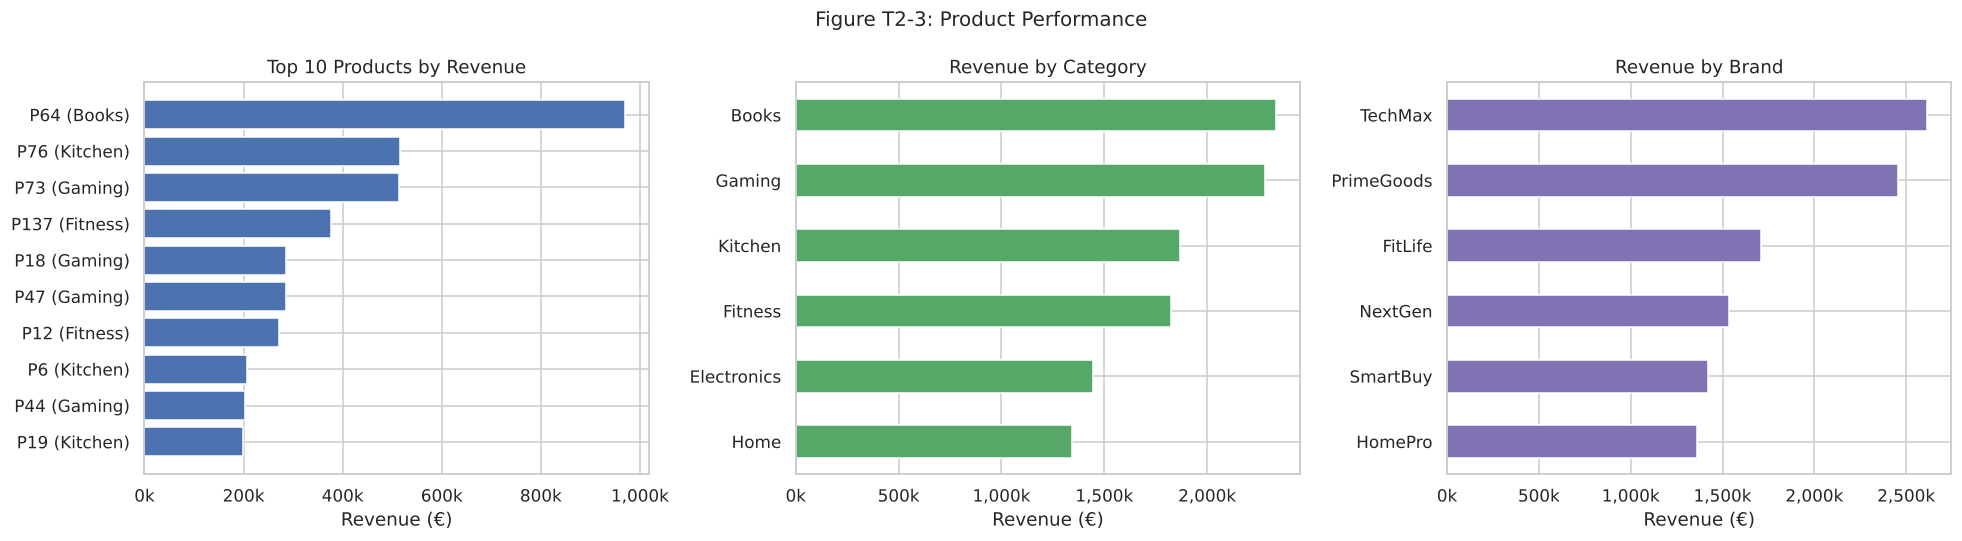

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
tp = top_products.sort_values("Revenue")
axes[0].barh([f"P{i} ({c})" for i, c in zip(tp.index, tp["Category"])], tp["Revenue"], color="#4C72B0")
axes[0].set_title("Top 10 Products by Revenue"); axes[0].set_xlabel("Revenue (€)")
cat_rev["Revenue"].sort_values().plot(kind="barh", ax=axes[1], color="#55A868")
axes[1].set_title("Revenue by Category"); axes[1].set_xlabel("Revenue (€)"); axes[1].set_ylabel("")
brand_rev["Revenue"].sort_values().plot(kind="barh", ax=axes[2], color="#8172B3")
axes[2].set_title("Revenue by Brand"); axes[2].set_xlabel("Revenue (€)"); axes[2].set_ylabel("")
for ax in axes:
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x/1000:,.0f}k"))
fig.suptitle("Figure T2-3: Product Performance", fontsize=13)
plt.tight_layout()
plt.savefig(FIG_DIR + "t2_fig03_product_performance.png", bbox_inches="tight")
plt.show()

In [26]:
# Do price or rating explain how well a product sells?
print(prod[["Revenue", "Buyers", "UnitsSold", "Price", "Rating"]].corr().loc[["Price", "Rating"], ["Revenue", "Buyers", "UnitsSold"]])

        Revenue  Buyers  UnitsSold
Price     -0.13   -0.19      -0.12
Rating     0.12    0.04       0.10


### 5.4 Key product observations
* **One product dominates:** Product 64 (Books, PrimeGoods, €180) generates ≈€970k, **8.7% of all revenue** on its own. The top 10 products (5% of the catalogue) generate ≈34.5% of revenue.
* **Books (≈21%) and Gaming (≈21%) are the largest categories.** Gaming earns the most revenue per product listed (≈€84k), so its range is the most productive. Home and Electronics are the weakest per product.
* **TechMax and PrimeGoods together earn ≈46% of revenue.** PrimeGoods has the highest revenue per product (≈€74k), boosted by Product 64.
* **Price and rating barely explain sales** (r ≈ −0.13 and +0.12 with revenue). Several top products are low-priced (e.g. P76 €21, P137 €25), and the #7 product (P12) has a poor 2.6 rating yet still sells well.

## 6. GroupBy & Pivot Table Analysis
### 6.1 GroupBy 3 – Spend by loyalty level

In [27]:
loyalty_order = ["Bronze", "Silver", "Gold"]
gb_loyalty = (cust.groupby("LoyaltyLevel")
              .agg(Customers=("TotalSpend", "size"), AvgSpend=("TotalSpend", "mean"),
                   TotalSpend=("TotalSpend", "sum"), AvgUnits=("TotalQuantity", "mean"),
                   AvgProducts=("UniqueProducts", "mean"), AvgRecency=("RecencyDays", "mean"),
                   AvgMembershipYears=("MembershipYears", "mean"))
              .reindex(loyalty_order))
gb_loyalty["RevenueShare%"] = gb_loyalty["TotalSpend"] / gb_loyalty["TotalSpend"].sum() * 100
gb_loyalty.to_csv(TABLE_DIR + "t2_groupby_loyalty.csv")
gb_loyalty

,Customers,AvgSpend,TotalSpend,AvgUnits,AvgProducts,AvgRecency,AvgMembershipYears,RevenueShare%
LoyaltyLevel,,,,,,,,
Bronze,493,"11,024.24","5,434,949.05",45.56,9.99,25.11,7.80,48.97
Silver,320,"11,132.31","3,562,339.29",46.39,10.37,26.58,6.91,32.10
Gold,187,"11,238.35","2,101,572.03",46.23,10.81,23.00,7.62,18.94


### 6.2 GroupBy 4 – Spend by age group

In [28]:
gb_age = (cust.groupby("AgeGroup")
          .agg(Customers=("TotalSpend", "size"), AvgSpend=("TotalSpend", "mean"),
               TotalSpend=("TotalSpend", "sum"), AvgUnits=("TotalQuantity", "mean"),
               AvgCategories=("UniqueCategories", "mean")))
gb_age["RevenueShare%"] = gb_age["TotalSpend"] / gb_age["TotalSpend"].sum() * 100
gb_age.to_csv(TABLE_DIR + "t2_groupby_agegroup.csv")
gb_age

,Customers,AvgSpend,TotalSpend,AvgUnits,AvgCategories,RevenueShare%
AgeGroup,,,,,,
18-25,245,"11,338.97","2,778,048.64",47.21,4.84,25.03
26-35,267,"10,966.08","2,927,943.83",45.02,4.70,26.38
36-50,251,"11,123.59","2,792,020.71",45.95,4.85,25.16
50+,237,"10,974.04","2,600,847.19",45.70,4.91,23.43


### 6.3 GroupBy 5 – Spend by region

In [29]:
gb_cregion = (cust.groupby("Region")
              .agg(Customers=("TotalSpend", "size"), AvgSpend=("TotalSpend", "mean"),
                   TotalSpend=("TotalSpend", "sum"), AvgUnits=("TotalQuantity", "mean"))
              .sort_values("TotalSpend", ascending=False))
gb_cregion.to_csv(TABLE_DIR + "t2_groupby_customer_region.csv")
gb_cregion

,Customers,AvgSpend,TotalSpend,AvgUnits
Region,,,,
South,261,"11,259.70","2,938,782.78",47.20
West,252,"11,287.05","2,844,336.41",46.38
North,247,"11,116.38","2,745,746.79",46.40
East,240,"10,708.31","2,569,994.39",43.69


### 6.4 GroupBy 6 – Membership tenure vs spend

In [30]:
cust["TenureBand"] = pd.cut(cust["MembershipYears"], bins=[0, 3, 6, 10, 14],
                            labels=["1-3 yrs", "4-6 yrs", "7-10 yrs", "11-14 yrs"])
gb_tenure = cust.groupby("TenureBand", observed=True).agg(
    Customers=("TotalSpend", "size"), AvgSpend=("TotalSpend", "mean"), AvgUnits=("TotalQuantity", "mean"))
gb_tenure

,Customers,AvgSpend,AvgUnits
TenureBand,,,
1-3 yrs,229,"10,880.56",45.48
4-6 yrs,190,"11,708.52",47.74
7-10 yrs,307,"10,986.17",45.86
11-14 yrs,274,"10,984.81",45.21


### 6.5 Pivot Table 1 – Revenue by Age Group × Category

In [31]:
pv_age_cat = pd.pivot_table(full, values="Spend", index="AgeGroup", columns="Category",
                            aggfunc="sum", margins=True, margins_name="Total")
pv_age_cat.to_csv(TABLE_DIR + "t2_pivot_age_category.csv")
pv_age_cat

Category,Books,Electronics,Fitness,Gaming,Home,Kitchen,Total
AgeGroup,,,,,,,
18-25,"592,842.28","359,933.68","466,330.57","556,684.25","348,671.69","453,586.17","2,778,048.64"
26-35,"630,666.33","361,184.23","475,271.84","583,173.16","339,792.59","537,855.68","2,927,943.83"
36-50,"560,405.97","391,587.37","459,391.53","597,983.68","334,569.97","448,082.19","2,792,020.71"
50+,"551,289.89","332,933.37","425,617.34","543,424.67","319,069.28","428,512.64","2,600,847.19"
Total,"2,335,204.47","1,445,638.65","1,826,611.28","2,281,265.76","1,342,103.53","1,868,036.68","11,098,860.37"


In [32]:
# Row percentages: within each age group, what share of spend goes to each category?
pv_age_cat_pct = pv_age_cat.drop(index="Total", columns="Total")
pv_age_cat_pct = pv_age_cat_pct.div(pv_age_cat_pct.sum(axis=1), axis=0) * 100
pv_age_cat_pct.round(1)

Category,Books,Electronics,Fitness,Gaming,Home,Kitchen
AgeGroup,,,,,,
18-25,21.30,13.00,16.80,20.00,12.60,16.30
26-35,21.50,12.30,16.20,19.90,11.60,18.40
36-50,20.10,14.00,16.50,21.40,12.00,16.00
50+,21.20,12.80,16.40,20.90,12.30,16.50


### 6.6 Pivot Table 2 – Average spend per customer by Loyalty Level × Category

In [33]:
cust_cat = full.groupby(["CustomerID", "LoyaltyLevel", "Category"])["Spend"].sum().reset_index()
pv_loyal_cat = pd.pivot_table(cust_cat, values="Spend", index="LoyaltyLevel", columns="Category",
                              aggfunc="mean").reindex(loyalty_order)
pv_loyal_cat.to_csv(TABLE_DIR + "t2_pivot_loyalty_category.csv")
pv_loyal_cat

Category,Books,Electronics,Fitness,Gaming,Home,Kitchen
LoyaltyLevel,,,,,,
Bronze,"2,742.18","1,631.35","2,354.99","2,878.98","1,791.09","2,399.56"
Silver,"2,805.17","1,822.71","2,302.34","2,728.33","1,741.32","2,502.29"
Gold,"2,479.92","1,767.52","2,234.93","2,984.15","1,745.41","2,370.05"


### 6.7 Pivot Table 3 – Revenue by Region × Brand

In [34]:
pv_region_brand = pd.pivot_table(full, values="Spend", index="Region", columns="Brand",
                                 aggfunc="sum", margins=True, margins_name="Total")
pv_region_brand.to_csv(TABLE_DIR + "t2_pivot_region_brand.csv")
pv_region_brand

Brand,FitLife,HomePro,NextGen,PrimeGoods,SmartBuy,TechMax,Total
Region,,,,,,,
East,"402,129.33","322,795.10","371,224.85","546,471.80","324,870.71","602,502.60","2,569,994.39"
North,"416,539.45","369,450.77","337,110.99","629,238.38","348,578.93","644,828.27","2,745,746.79"
South,"483,890.70","298,317.48","423,638.14","652,080.11","379,712.22","701,144.13","2,938,782.78"
West,"409,494.86","368,517.51","404,994.01","626,891.78","367,495.64","666,942.61","2,844,336.41"
Total,"1,712,054.34","1,359,080.86","1,536,967.99","2,454,682.07","1,420,657.50","2,615,417.61","11,098,860.37"


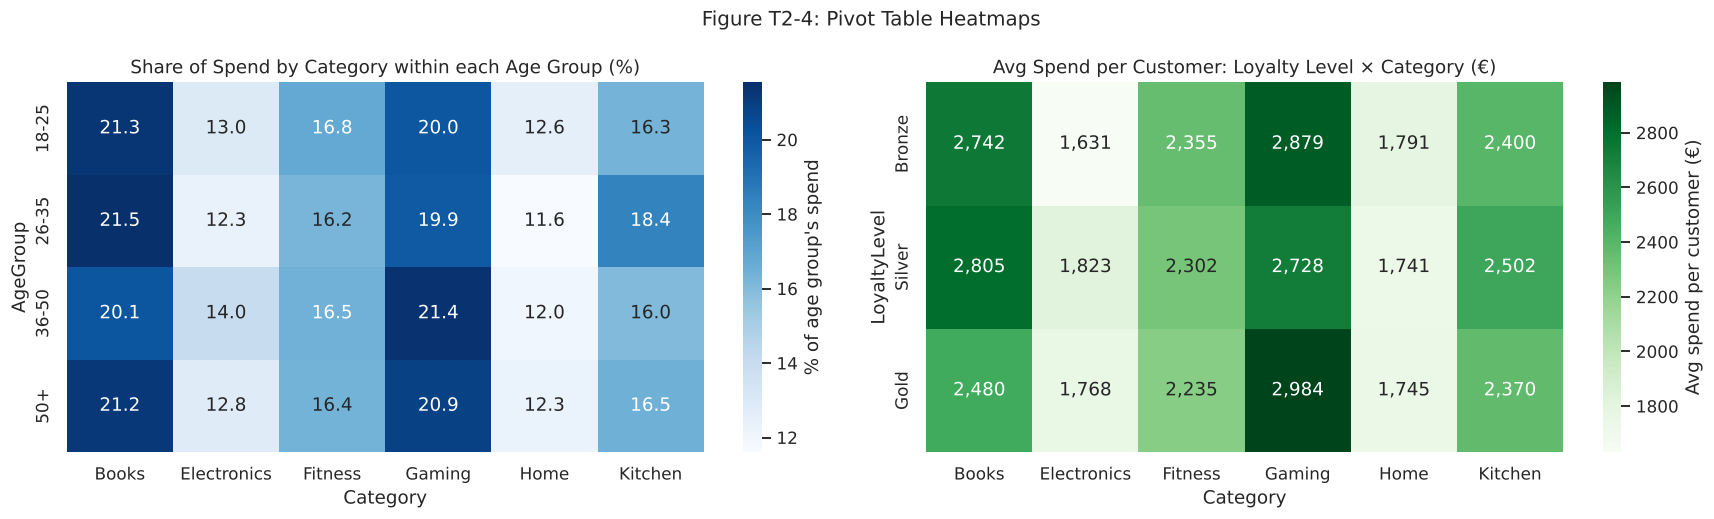

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
sns.heatmap(pv_age_cat_pct, annot=True, fmt=".1f", cmap="Blues", ax=axes[0],
            cbar_kws={"label": "% of age group's spend"})
axes[0].set_title("Share of Spend by Category within each Age Group (%)")
sns.heatmap(pv_loyal_cat, annot=True, fmt=",.0f", cmap="Greens", ax=axes[1],
            cbar_kws={"label": "Avg spend per customer (€)"})
axes[1].set_title("Avg Spend per Customer: Loyalty Level × Category (€)")
fig.suptitle("Figure T2-4: Pivot Table Heatmaps", fontsize=13)
plt.tight_layout()
plt.savefig(FIG_DIR + "t2_fig04_pivot_heatmaps.png", bbox_inches="tight")
plt.show()

### 6.8 Key GroupBy & Pivot observations
* **Loyalty level:** Gold customers spend only ≈2% more than Bronze on average (≈€11.2k vs ≈€11.0k), with similar frequency and recency. The loyalty programme is not producing measurably higher spend.
* **Age group:** average spend (≈€11.0k–€11.3k) and category mix are almost identical across ages. Books and Gaming take ≈20–21% of every age group's spend, so age-based targeting has limited value here.
* **Region:** East customers spend slightly less (≈€10.7k vs ≈€11.1k–€11.3k elsewhere).
* **Tenure:** no upward trend in spend with membership years.
* **Region × Brand:** TechMax and PrimeGoods lead in every region. South is the strongest region for most brands.
* **Takeaway:** demographic segments behave very similarly. Individual purchase behaviour, which collaborative filtering uses, is a better basis for personalisation than age, region or loyalty tier.

## 7. Recommendation System Development
Three approaches are built so they can be compared fairly:

| # | Method | How it works | Why use it |
|---|---|---|---|
| 1 | **Popularity-based** | Recommends the products bought by the most customers, excluding ones the customer already owns | Simple, robust baseline; works for new customers with no history (cold start) |
| 2 | **Item-based Collaborative Filtering** | Finds products bought by the *same customers* as the ones this customer bought (cosine similarity on the interaction matrix) | Learns "customers who bought X also bought Y" patterns; personalised |
| 3 | **Content-based Filtering** | Recommends products with similar *attributes* (category, brand, price, rating) to the customer's past purchases | Personalised; can recommend new or rarely bought products |

### 7.1 Train / test split for evaluation
To evaluate fairly, each customer's **most recent** purchases are hidden. Using `MostRecentDays` (the lowest `LastPurchaseDays`), the most recent ~20% of each customer's products (at least 1) form the **test set**. The models only see the older purchases (**train set**) and are scored on whether they recommend the products the customer actually bought next. This mirrors real use: predicting the *next* purchase.

In [36]:
def temporal_split(inter, test_frac=0.2, min_items=3):
    train_parts, test_parts = [], []
    for cid, g in inter.groupby("CustomerID"):
        g = g.sort_values("MostRecentDays")  # most recent first
        if len(g) < min_items:
            train_parts.append(g)  # too few items to test on; keep for training only
            continue
        n_test = max(1, int(round(len(g) * test_frac)))
        test_parts.append(g.iloc[:n_test])
        train_parts.append(g.iloc[n_test:])
    return pd.concat(train_parts), pd.concat(test_parts)

train_inter, test_inter = temporal_split(interactions)
print(f"Train interactions: {len(train_inter):,}   Test interactions: {len(test_inter):,}")
print(f"Customers evaluated: {test_inter['CustomerID'].nunique():,}")

all_products = products["ProductID"].sort_values().values
train_matrix = (train_inter.pivot_table(index="CustomerID", columns="ProductID", values="Quantity",
                                        aggfunc="sum", fill_value=0)
                .reindex(columns=all_products, fill_value=0))
train_owned = train_inter.groupby("CustomerID")["ProductID"].apply(set).to_dict()
test_truth = test_inter.groupby("CustomerID")["ProductID"].apply(set).to_dict()

Train interactions: 8,210   Test interactions: 2,053
Customers evaluated: 943


### 7.2 Method 1 – Popularity-based recommender

In [37]:
class PopularityRecommender:
    """Ranks products by number of distinct buyers (ties broken by units sold)."""
    def fit(self, inter):
        pop = inter.groupby("ProductID").agg(Buyers=("CustomerID", "nunique"), Units=("Quantity", "sum"))
        self.ranking = pop.sort_values(["Buyers", "Units"], ascending=False).index.tolist()
        self.scores = pop
        return self

    def recommend(self, customer_id, owned, k=K):
        return [p for p in self.ranking if p not in owned][:k]

pop_model = PopularityRecommender().fit(train_inter)
print("Top 10 most popular products (train data):")
pop_model.scores.loc[pop_model.ranking[:10]].join(products.set_index("ProductID")[["Category", "Brand", "Price"]])

Top 10 most popular products (train data):


,Buyers,Units,Category,Brand,Price
ProductID,,,,,
137,115,975,Fitness,NextGen,24.58
73,114,655,Gaming,TechMax,415.14
198,106,810,Fitness,PrimeGoods,20.24
114,106,502,Home,PrimeGoods,321.76
44,103,698,Gaming,TechMax,136.66
6,103,459,Kitchen,SmartBuy,359.14
12,102,1028,Fitness,PrimeGoods,422.56
186,99,379,Electronics,TechMax,266.38
155,98,362,Books,FitLife,441.57


### 7.3 Method 2 – Item-based Collaborative Filtering
1. Convert the train interaction matrix to binary (bought / not bought), so heavy buyers don't dominate.
2. Compute **cosine similarity** between every pair of products, based on which customers bought them.
3. For each customer, score every unseen product by summing its similarity to the products they already own, then recommend the top K.

In [38]:
class ItemCFRecommender:
    def fit(self, matrix):
        binary = (matrix > 0).astype(float)
        self.products = matrix.columns.values
        sim = cosine_similarity(binary.T.values)
        np.fill_diagonal(sim, 0)
        self.sim = pd.DataFrame(sim, index=self.products, columns=self.products)
        self.fallback = binary.sum().sort_values(ascending=False).index.tolist()  # popularity for cold start
        return self

    def score(self, owned):
        owned = [p for p in owned if p in self.sim.index]
        if not owned:
            return pd.Series(dtype=float)
        return self.sim.loc[owned].sum(axis=0)

    def recommend(self, customer_id, owned, k=K):
        s = self.score(owned)
        if s.empty:
            return [p for p in self.fallback if p not in owned][:k]
        s = s.drop(labels=list(owned), errors="ignore")
        return s.sort_values(ascending=False).head(k).index.tolist()

cf_model = ItemCFRecommender().fit(train_matrix)
print("Item–item similarity matrix:", cf_model.sim.shape)

# Example: products most similar to the single most popular product
p0 = pop_model.ranking[0]
print(f"\nProducts most often bought by the same customers as Product {p0} "
      f"({products.set_index('ProductID').loc[p0, 'Category']}):")
cf_model.sim[p0].sort_values(ascending=False).head(5).to_frame("CosineSimilarity").join(
    products.set_index("ProductID")[["Category", "Brand", "Price"]])

Item–item similarity matrix: (200, 200)

Products most often bought by the same customers as Product 137 (Fitness):


,CosineSimilarity,Category,Brand,Price
73,0.61,Gaming,TechMax,415.14
198,0.58,Fitness,PrimeGoods,20.24
155,0.56,Books,FitLife,441.57
8,0.52,Home,TechMax,99.46
48,0.51,Gaming,FitLife,273.31


### 7.4 Method 3 – Content-based Filtering
Each product becomes a feature vector: one-hot **Category** and **Brand**, plus scaled **Price** and **Rating**. A customer profile is the spend-weighted average of the vectors of products they bought. Unseen products are ranked by cosine similarity to that profile.

In [39]:
class ContentRecommender:
    def fit(self, products_df, inter, cat_weight=2.0):
        p = products_df.set_index("ProductID").loc[all_products]
        enc = OneHotEncoder(sparse_output=False).fit(p[["Category", "Brand"]])
        onehot = enc.transform(p[["Category", "Brand"]])
        n_cat = p["Category"].nunique()
        onehot[:, :n_cat] *= cat_weight  # category matters more than brand for substitutes
        numeric = MinMaxScaler().fit_transform(p[["Price", "Rating"]])
        self.features = pd.DataFrame(np.hstack([onehot, numeric]), index=p.index)
        self.spend = inter.set_index(["CustomerID", "ProductID"])["Spend"]
        return self

    def recommend(self, customer_id, owned, k=K):
        owned = list(owned)
        w = self.spend.loc[customer_id].reindex(owned).fillna(0).values if customer_id in self.spend.index.get_level_values(0) else np.ones(len(owned))
        if w.sum() == 0:
            w = np.ones(len(owned))
        profile = np.average(self.features.loc[owned].values, axis=0, weights=w)
        sims = cosine_similarity(profile.reshape(1, -1), self.features.values)[0]
        s = pd.Series(sims, index=self.features.index).drop(labels=owned, errors="ignore")
        return s.sort_values(ascending=False).head(k).index.tolist()

cb_model = ContentRecommender().fit(products, train_inter)
print("Product feature matrix:", cb_model.features.shape)

Product feature matrix: (200, 14)


## 8. Evaluation & Comparison
**Metrics (top-10 recommendations, averaged over customers):**
* **Precision@10** – share of the 10 recommendations that the customer actually bought next.
* **Recall@10** – share of the customer's next purchases that appeared in the 10 recommendations.
* **Hit Rate@10** – share of customers for whom at least one recommendation was correct.
* **Catalogue coverage** – share of the 200 products that get recommended to anyone (higher = less "same items for everyone").
* **Avg price of recommended items** – a commercial indicator of basket value.

A **random recommender** is included as a lower benchmark.

In [40]:
class RandomRecommender:
    def __init__(self, seed=RANDOM_STATE):
        self.rng = np.random.default_rng(seed)
    def recommend(self, customer_id, owned, k=K):
        cand = [p for p in all_products if p not in owned]
        return list(self.rng.choice(cand, size=k, replace=False))

price_lookup = products.set_index("ProductID")["Price"]

def evaluate(model, name, k=K):
    precisions, recalls, hits, recommended = [], [], [], set()
    rec_prices = []
    for cid, truth in test_truth.items():
        owned = train_owned.get(cid, set())
        recs = model.recommend(cid, owned, k)
        recommended.update(recs)
        rec_prices.extend(price_lookup.loc[recs].values)
        n_hit = len(set(recs) & truth)
        precisions.append(n_hit / k)
        recalls.append(n_hit / len(truth))
        hits.append(n_hit > 0)
    return {"Method": name,
            f"Precision@{k}": np.mean(precisions),
            f"Recall@{k}": np.mean(recalls),
            f"HitRate@{k}": np.mean(hits),
            "Coverage": len(recommended) / len(all_products),
            "AvgRecPrice": np.mean(rec_prices)}

models = {"Random (benchmark)": RandomRecommender(),
          "Popularity-based": pop_model,
          "Item-based CF": cf_model,
          "Content-based": cb_model}
eval_df = pd.DataFrame([evaluate(m, n) for n, m in models.items()]).set_index("Method")
eval_df["Lift vs Random (Recall)"] = eval_df[f"Recall@{K}"] / eval_df.loc["Random (benchmark)", f"Recall@{K}"]
eval_df.to_csv(TABLE_DIR + "t2_recommender_evaluation.csv")
eval_df

,Precision@10,Recall@10,HitRate@10,Coverage,AvgRecPrice,Lift vs Random (Recall)
Method,,,,,,
Random (benchmark),0.01,0.05,0.10,1.00,260.96,1.00
Popularity-based,0.05,0.23,0.41,0.08,252.41,4.47
Item-based CF,0.16,0.74,0.91,0.88,227.69,14.67
Content-based,0.01,0.04,0.09,0.99,304.20,0.77


### 8.1 Hybrid recommender (CF + Popularity)
Collaborative filtering and popularity capture different signals, so a simple **weighted hybrid** is tested: normalised CF score + α × normalised popularity score. α is tuned on a validation split carved out of the *training* data, so the test set stays untouched.

In [41]:
class HybridRecommender:
    def __init__(self, cf, pop_scores, alpha=0.5):
        self.cf, self.alpha = cf, alpha
        b = pop_scores["Buyers"].reindex(all_products).fillna(0)
        self.pop_norm = (b - b.min()) / (b.max() - b.min())

    def recommend(self, customer_id, owned, k=K):
        s = self.cf.score(owned)
        if s.empty:
            s = pd.Series(0.0, index=all_products)
        s = (s - s.min()) / (s.max() - s.min() + 1e-9)
        total = s.add(self.alpha * self.pop_norm, fill_value=0).drop(labels=list(owned), errors="ignore")
        return total.sort_values(ascending=False).head(k).index.tolist()

# Validation split inside the training data (most recent train items held out)
tr2, val2 = temporal_split(train_inter)
tr2_matrix = (tr2.pivot_table(index="CustomerID", columns="ProductID", values="Quantity", aggfunc="sum", fill_value=0)
              .reindex(columns=all_products, fill_value=0))
tr2_owned = tr2.groupby("CustomerID")["ProductID"].apply(set).to_dict()
val_truth = val2.groupby("CustomerID")["ProductID"].apply(set).to_dict()
cf_val = ItemCFRecommender().fit(tr2_matrix)
pop_val = PopularityRecommender().fit(tr2)

alpha_scores = {}
for a in [0, 0.25, 0.5, 1, 2, 4]:
    h = HybridRecommender(cf_val, pop_val.scores, alpha=a)
    r = [len(set(h.recommend(c, tr2_owned.get(c, set()))) & t) / len(t) for c, t in val_truth.items()]
    alpha_scores[a] = np.mean(r)
alpha_df = pd.Series(alpha_scores, name=f"Validation Recall@{K}").to_frame()
best_alpha = max(alpha_scores, key=alpha_scores.get)
print("Best alpha on validation data:", best_alpha)
alpha_df

Best alpha on validation data: 0.5


,Validation Recall@10
0.00,0.64
0.25,0.65
0.50,0.65
1.00,0.64
2.00,0.51
4.00,0.40


In [42]:
hybrid_model = HybridRecommender(cf_model, pop_model.scores, alpha=best_alpha)
models["Hybrid (CF + Popularity)"] = hybrid_model
eval_df.loc["Hybrid (CF + Popularity)"] = evaluate(hybrid_model, "Hybrid (CF + Popularity)")
eval_df["Lift vs Random (Recall)"] = eval_df[f"Recall@{K}"] / eval_df.loc["Random (benchmark)", f"Recall@{K}"]
eval_df.to_csv(TABLE_DIR + "t2_recommender_evaluation.csv")
eval_df

,Precision@10,Recall@10,HitRate@10,Coverage,AvgRecPrice,Lift vs Random (Recall)
Method,,,,,,
Random (benchmark),0.01,0.05,0.10,1.00,260.96,1.00
Popularity-based,0.05,0.23,0.41,0.08,252.41,4.47
Item-based CF,0.16,0.74,0.91,0.88,227.69,14.67
Content-based,0.01,0.04,0.09,0.99,304.20,0.77
Hybrid (CF + Popularity),0.16,0.76,0.93,0.83,223.74,15.13


In [43]:
# Sensitivity: how do the methods compare at different list lengths?
k_rows = []
for k in [5, 10, 20]:
    for n, m in models.items():
        res = evaluate(m, n, k=k)
        k_rows.append({"Method": n, "K": k, "Recall": res[f"Recall@{k}"], "HitRate": res[f"HitRate@{k}"]})
k_df = pd.DataFrame(k_rows)
k_df.pivot(index="Method", columns="K", values="Recall").rename(columns=lambda c: f"Recall@{c}")

K,Recall@5,Recall@10,Recall@20
Method,,,
Content-based,0.01,0.04,0.08
Hybrid (CF + Popularity),0.62,0.76,0.91
Item-based CF,0.56,0.74,0.92
Popularity-based,0.12,0.23,0.38
Random (benchmark),0.03,0.05,0.11


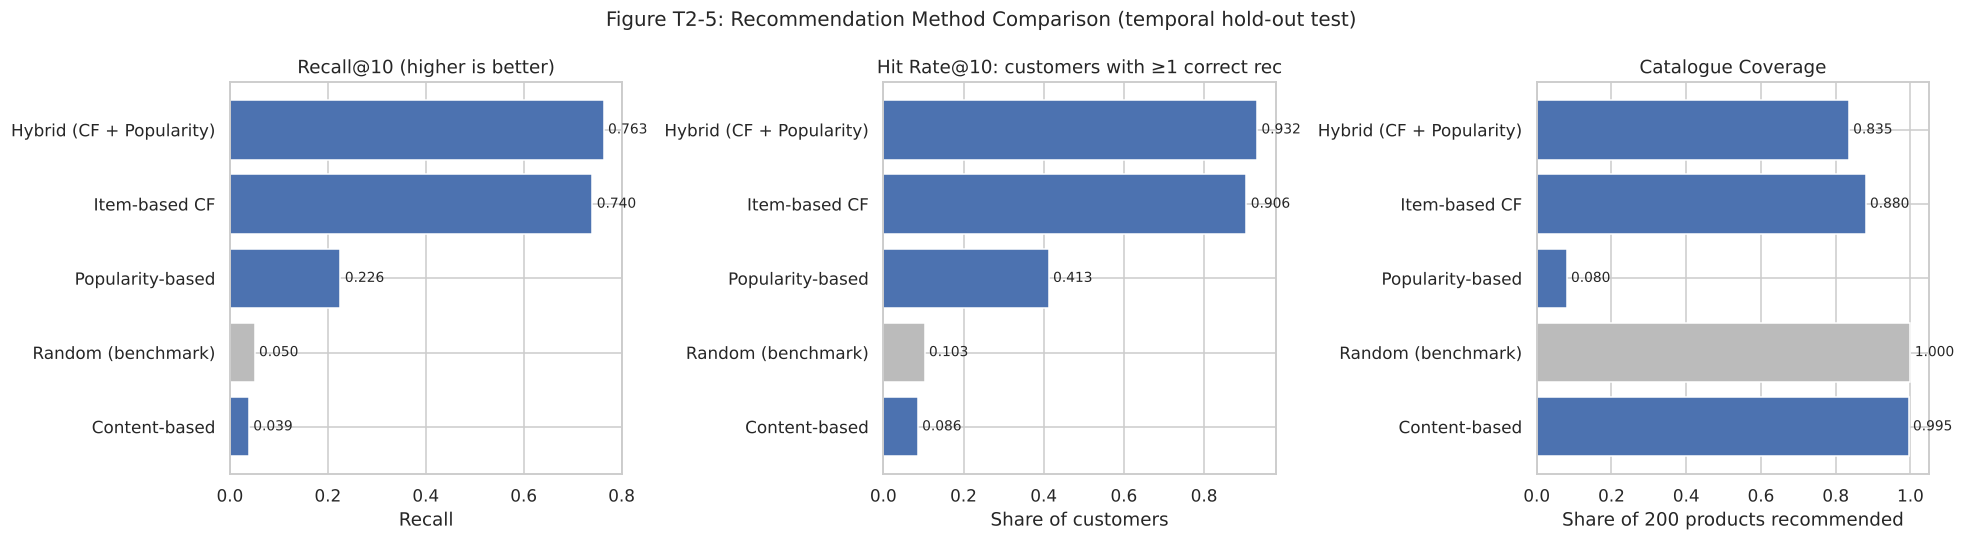

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
order = eval_df.sort_values(f"Recall@{K}").index
colors = ["#BBBBBB" if "Random" in m else "#4C72B0" for m in order]
axes[0].barh(order, eval_df.loc[order, f"Recall@{K}"], color=colors)
axes[0].set_title(f"Recall@{K} (higher is better)"); axes[0].set_xlabel("Recall")
axes[1].barh(order, eval_df.loc[order, f"HitRate@{K}"], color=colors)
axes[1].set_title(f"Hit Rate@{K}: customers with ≥1 correct rec"); axes[1].set_xlabel("Share of customers")
axes[2].barh(order, eval_df.loc[order, "Coverage"], color=colors)
axes[2].set_title("Catalogue Coverage"); axes[2].set_xlabel("Share of 200 products recommended")
for ax, col in zip(axes, [f"Recall@{K}", f"HitRate@{K}", "Coverage"]):
    for i, m in enumerate(order):
        ax.text(eval_df.loc[m, col], i, f" {eval_df.loc[m, col]:.3f}", va="center", fontsize=9)
fig.suptitle("Figure T2-5: Recommendation Method Comparison (temporal hold-out test)", fontsize=13)
plt.tight_layout()
plt.savefig(FIG_DIR + "t2_fig05_recommender_comparison.png", bbox_inches="tight")
plt.show()

### 8.2 Key evaluation observations
* **Item-based CF and the Hybrid are by far the strongest methods.** The Hybrid recovers ≈76% of each customer's next purchases in its top 10 (Recall@10), and gets at least one right for ≈93% of customers. That is about **15× better than random** and over 3× better than popularity.
* **The Hybrid (CF + popularity, α = 0.5) performs best overall.** Its advantage is clearest for short lists: Recall@5 ≈0.62 vs 0.56 for pure CF. This matters for email/app slots that only show a few items.
* **Popularity is a useful but weak baseline.** It beats random (Recall@10 ≈0.23) but shows almost everyone the same items (8% catalogue coverage), so it is best kept for brand-new customers with no history.
* **Content-based filtering performs no better than random** (Recall@10 ≈0.04). Customers buy across ≈5 of the 6 categories, and products bought together are usually from *different* categories (see the CF similarity example). Recommending "more of the same category" does not match real behaviour in this data.
* **Coverage:** CF/Hybrid recommend ≈83–88% of the catalogue, so they also expose long-tail products rather than only best-sellers.
* **Limitations:** the test uses `LastPurchaseDays` as a proxy for time order. The data has no explicit ratings, and results come from one historical snapshot. An online A/B test would be needed to confirm the uplift in real sales.

## 9. Recommendations for Example Customers
Five customers are chosen to show different profiles: a top spender, a typical Gold member, a recent customer with very little history, a valuable "At Risk" customer and a long-inactive "Hibernating" customer. Final recommendations use the models re-trained on **all** purchase history.

In [45]:
# Re-train every model on the full data for production-style recommendations
full_matrix = interaction_matrix.reindex(columns=all_products, fill_value=0)
owned_all = interactions.groupby("CustomerID")["ProductID"].apply(set).to_dict()
pop_full = PopularityRecommender().fit(interactions)
cf_full = ItemCFRecommender().fit(full_matrix)
cb_full = ContentRecommender().fit(products, interactions)
hy_full = HybridRecommender(cf_full, pop_full.scores, alpha=best_alpha)

gold = cust[cust["LoyaltyLevel"] == "Gold"].sort_values("TotalSpend")
candidates = [
    top_spend.index[0],                                                                      # top spender
    gold.index[len(gold) // 2],                                                              # typical Gold member
    cust[cust["Segment"] == "New / Promising"].sort_values("UniqueProducts").index[0],      # recent, very little history
    cust[cust["Segment"] == "At Risk"].sort_values("TotalSpend", ascending=False).index[0],  # valuable but lapsing
    cust[cust["Segment"] == "Hibernating"].sort_values("RecencyDays", ascending=False).index[0],  # long inactive
]
example_ids = list(dict.fromkeys(candidates))
assert len(example_ids) == 5
cust.loc[example_ids, ["AgeGroup", "Region", "LoyaltyLevel", "MembershipYears", "Segment",
                       "TotalSpend", "UniqueProducts", "RecencyDays"]]

,AgeGroup,Region,LoyaltyLevel,MembershipYears,Segment,TotalSpend,UniqueProducts,RecencyDays
CustomerID,,,,,,,,
729,18-25,East,Bronze,1,Champions,"23,828.03",15,5
169,26-35,West,Gold,6,Need Attention,"11,525.28",10,2
47,50+,South,Bronze,1,New / Promising,612.90,1,4
946,18-25,West,Bronze,14,At Risk,"15,949.69",11,26
38,36-50,East,Silver,1,Hibernating,"1,872.23",2,304


In [46]:
pinfo = products.set_index("ProductID")

def describe_recs(recs):
    return [f"P{p} {pinfo.loc[p, 'Category']}/{pinfo.loc[p, 'Brand']} €{pinfo.loc[p, 'Price']:.0f}" for p in recs]

example_rows = []
for cid in example_ids:
    owned = owned_all[cid]
    hist_cats = full[full["CustomerID"] == cid].groupby("Category")["Spend"].sum().sort_values(ascending=False)
    print("=" * 100)
    c = cust.loc[cid]
    print(f"Customer {cid} | {c['AgeGroup']} | {c['Region']} | {c['LoyaltyLevel']} | Segment: {c['Segment']} | "
          f"Spend €{c['TotalSpend']:,.0f} | {len(owned)} products owned")
    print("  Top categories by past spend:", ", ".join(f"{k} (€{v:,.0f})" for k, v in hist_cats.head(3).items()))
    for name, m in [("Popularity", pop_full), ("Item-CF", cf_full), ("Content", cb_full), ("Hybrid", hy_full)]:
        recs = m.recommend(cid, owned, k=5)
        print(f"  {name:<11}: " + " | ".join(describe_recs(recs)))
        for rank, p in enumerate(recs, 1):
            example_rows.append({"CustomerID": cid, "Method": name, "Rank": rank, "ProductID": p,
                                 "Category": pinfo.loc[p, "Category"], "Brand": pinfo.loc[p, "Brand"],
                                 "Price": pinfo.loc[p, "Price"]})
example_recs = pd.DataFrame(example_rows)
example_recs.to_csv(TABLE_DIR + "t2_example_customer_recommendations.csv", index=False)

Customer 729 | 18-25 | East | Bronze | Segment: Champions | Spend €23,828 | 15 products owned
  Top categories by past spend: Books (€8,391), Electronics (€6,840), Home (€3,517)
  Popularity : P12 Fitness/PrimeGoods €423 | P64 Books/PrimeGoods €180 | P76 Kitchen/FitLife €21 | P137 Fitness/NextGen €25 | P198 Fitness/PrimeGoods €20
  Item-CF    : P134 Home/HomePro €290 | P50 Gaming/HomePro €141 | P142 Fitness/HomePro €458 | P49 Kitchen/TechMax €419 | P37 Home/SmartBuy €115
  Content    : P72 Books/TechMax €422 | P3 Books/TechMax €176 | P184 Books/TechMax €394 | P26 Books/TechMax €219 | P53 Books/TechMax €442
  Hybrid     : P134 Home/HomePro €290 | P50 Gaming/HomePro €141 | P142 Fitness/HomePro €458 | P49 Kitchen/TechMax €419 | P37 Home/SmartBuy €115
Customer 169 | 26-35 | West | Gold | Segment: Need Attention | Spend €11,525 | 10 products owned
  Top categories by past spend: Gaming (€4,332), Kitchen (€3,613), Books (€2,726)
  Popularity : P12 Fitness/PrimeGoods €423 | P64 Books/PrimeGoo

In [47]:
# Side-by-side table of the Top-5 hybrid (recommended method) for each example customer
example_recs[example_recs["Method"] == "Hybrid"].pivot(index="Rank", columns="CustomerID", values="ProductID")

CustomerID,38,47,169,729,946
Rank,,,,,
1,198,137,187,134,106
2,73,198,95,50,59
3,137,73,50,142,3
4,8,8,78,49,163
5,155,127,142,37,195


In [48]:
# How personalised is each method? Average overlap between the 5 example customers' lists (lower = more personal)
from itertools import combinations
overlap_rows = []
for name in ["Popularity", "Item-CF", "Content", "Hybrid"]:
    lists = [set(example_recs[(example_recs["Method"] == name) & (example_recs["CustomerID"] == c)]["ProductID"]) for c in example_ids]
    ov = [len(a & b) / 5 for a, b in combinations(lists, 2)]
    overlap_rows.append({"Method": name, "AvgOverlapBetweenCustomers": np.mean(ov)})
pd.DataFrame(overlap_rows).set_index("Method")

,AvgOverlapBetweenCustomers
Method,
Popularity,1.00
Item-CF,0.12
Content,0.08
Hybrid,0.12


### 9.1 Key observations on example recommendations
* **Popularity gives every customer essentially the same list** (100% overlap), whereas CF/Hybrid lists are personalised (≈12% overlap between customers).
* **Customer 729 (top spender, Champion):** the Hybrid suggests cross-category items (Home, Gaming, Fitness, Kitchen) beyond their Books/Electronics history, which is a cross-sell opportunity.
* **Customer 47 (new, 1 product):** with so little history, CF leans on widely bought items (P137, P198, P73). The cold-start problem is handled gracefully.
* **Customer 946 (At Risk, €16k lifetime spend):** personalised recommendations across Electronics, Home, Books and Kitchen could support a targeted win-back offer.
* **Customer 38 (Hibernating, 304 days inactive):** the Hybrid includes low-priced items (€20–€25), which suit a low-cost re-engagement offer.
* **Content-based lists stay inside one category/brand** (e.g. all Gaming/TechMax for customer 169), which explains its poor test performance.

## 10. Summary of Outputs
| Requirement | Where it is in this notebook |
|---|---|
| Load, inspect, combine datasets; data quality | Sections 1–3 |
| Customer–product interaction matrix | Section 3.2 (Figure T2-1) |
| Top 10 customers by spend & frequency; customer value analysis | Section 4 (RFM, Pareto – Figure T2-2) |
| Top 10 products, revenue by category & brand | Section 5 (Figure T2-3) |
| ≥3 GroupBy + ≥2 Pivot tables | Sections 5–6 (6 GroupBys, 3 Pivots – Figure T2-4) |
| Popularity-based + additional recommender(s) | Section 7 (Popularity, Item-CF, Content-based) + Hybrid (8.1) |
| Evaluation & comparison | Section 8 (Precision/Recall/HitRate/Coverage – Figure T2-5) |
| Recommendations for ≥5 example customers | Section 9 |

All tables are exported to `outputs/tables/` for use in the Task 3 report.